**SAPIANS** · SCC5819 · MÓDULO 06 — PFI · MOLNAR, CAP. 23

# O embaralhamento muda a coluna certa — e só ela?

Depois dos métodos locais, a PFI pergunta pela dependência preditiva global do mesmo modelo. O walkthrough mostra o experimento; este caderno confronta o núcleo com um oráculo independente e com a biblioteca.

[README do módulo](../README.md) · [outline da aula](../lecture/outline.md) · [walkthrough](pfi_walkthrough.ipynb) · [Colab](https://colab.research.google.com/github/wbendinelli/interpretable-ml-lectures/blob/main/modules/06-pfi/notebooks/pfi_internals.ipynb)

---

**Objetivos.** Conferir transporte posicional, preservação de categorias e de alvos, ausência de retreino, sinais e dispersão da importância; distinguir uma validação sintética dos registros reais do curso.


In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib


Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import itertools
import json
import os
import subprocess
from pathlib import Path
import sys
import tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from xgboost import XGBClassifier

REPO = Path(os.environ.get("INTERPRETABLE_ML_REPO", Path.cwd())).resolve()
while REPO != REPO.parent and not (REPO / "tools/srag_70_explain.py").exists():
    REPO = REPO.parent
if not (REPO / "tools/srag_70_explain.py").exists():
    REPO = Path(tempfile.gettempdir()) / "interpretable-ml-lectures"
    if not REPO.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/wbendinelli/interpretable-ml-lectures.git",
                        str(REPO)], check=True, capture_output=True)
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_70_explain as E
import srag_62_pfi as P
import srag_pfi_walkthrough as W
import srag_60_model as M
import srag_73_teaching_demo as H

WORK = Path(os.environ.get("PFI_WORK_DIR", tempfile.mkdtemp(prefix="pfi-internals-")))
WORK.mkdir(parents=True, exist_ok=True)
assert not WORK.is_relative_to(REPO)
os.chdir(WORK)
SP.aplicar()
RANDOM_STATE = 42
print("Semente dos exemplos sintéticos:", SP.pt_int(RANDOM_STATE))
print("Os testes sintéticos abaixo não medem desempenho do modelo SRAG.")


Semente dos exemplos sintéticos: 42
Os testes sintéticos abaixo não medem desempenho do modelo SRAG.


## §1 — O contrato que a aula executa

O núcleo recebe um preditor já ajustado. `permutar_colunas` copia a matriz original e seleciona os doadores por posição, preservando o índice de destino. Uma tupla de colunas usa a mesma linha doadora em todas elas. `trace_pfi` converte as probabilidades da classe positiva para precisão dupla e recebe a função de perda do chamador.

A ordem precisa ser uma bijeção das posições. A identidade é permitida: uma permutação aleatória não precisa mover todas as linhas. Para os subgrupos, a ordem é construída de modo que doador e destino pertençam ao mesmo grupo; isso condiciona apenas no agrupamento escolhido.


In [3]:
x = pd.DataFrame(
    {"signal": [0., 1., 2., 3., 4., 5.], "noise": [0., 1., 0., 1., 0., 1.]},
    index=[90, 3, 12, 5, 21, 7],
)
y = np.array([0, 0, 0, 1, 1, 1])
model = LogisticRegression(C=2, random_state=RANDOM_STATE).fit(x, y)
assert np.array_equal(model.classes_, [0, 1])
x_snapshot = x.copy(deep=True)
y_snapshot = y.copy()
identity = np.arange(len(x))
before, identity_after = E.trace_pfi(model, x, y, "signal", [identity], log_loss)
np.testing.assert_allclose(identity_after, before, rtol=0, atol=0)
pd.testing.assert_frame_equal(x, x_snapshot)
np.testing.assert_array_equal(y, y_snapshot)
print("Linhas sintéticas:", SP.pt_int(len(x)), "; índice propositalmente não sequencial.")
print("log loss original sintético:", SP.pt(before, 8))
print("Mudança com ordem identidade:", SP.pt(identity_after[0] - before, 8))
print("Classe positiva na segunda coluna; alvos e matriz original preservados.")


Linhas sintéticas: 6 ; índice propositalmente não sequencial.
log loss original sintético: 0,15968774
Mudança com ordem identidade: 0,00000000
Classe positiva na segunda coluna; alvos e matriz original preservados.


**O que olhar.** A identidade produz mudança nula. O índice deliberadamente fora de ordem detectaria o erro clássico de atribuir uma série embaralhada que pandas realinha pelos rótulos.

## §2 — Um oráculo independente: enumerar as ordens possíveis

Para uma matriz sintética pequena, podemos percorrer todas as permutações. O oráculo move diretamente uma coluna de um array NumPy, sem chamar o núcleo ou usar a atribuição de séries de pandas. Depois calcula a média dos perdas logarítmicas explicitamente. Comparamos cada perda, não apenas uma média que poderia ocultar erros de alinhamento.


In [4]:
all_orders = [np.asarray(order) for order in itertools.permutations(range(len(x)))]
exact_before, exact_after = E.trace_pfi(model, x, y, "signal", all_orders, log_loss)
raw = x.to_numpy()
oracle_errors = []
for order in all_orders:
    changed_array = raw.copy()
    changed_array[:, 0] = raw[order, 0]
    changed_frame = pd.DataFrame(changed_array, columns=x.columns)
    probability = model.predict_proba(changed_frame)[:, 1]
    oracle_errors.append(float(np.mean(np.where(y == 1, -np.log(probability), -np.log1p(-probability)))))
oracle_errors = np.asarray(oracle_errors)
np.testing.assert_allclose(exact_after, oracle_errors, rtol=0, atol=1e-15)
np.testing.assert_allclose(exact_before, before, rtol=0, atol=0)
wrapper_before, wrapper_after = W.trace_feature(model, x, y, "signal", all_orders, log_loss)
np.testing.assert_allclose(wrapper_after, exact_after, rtol=0, atol=0)
assert wrapper_before == exact_before
exact_delta = exact_after - exact_before
print("Ordens enumeradas:", SP.pt_int(len(all_orders)))
print("Maior discrepância núcleo versus oráculo:", SP.pt(np.max(np.abs(exact_after - oracle_errors)), 15))
print("Wrapper didático e núcleo: mesmos resultados em todas as ordens.")
print("PFI média da distribuição sintética exata:", SP.pt(exact_delta.mean(), 8))
print("SD da distribuição exata, ddof =", SP.pt_int(0), ":", SP.pt(exact_delta.std(ddof=0), 8))


Ordens enumeradas: 720
Maior discrepância núcleo versus oráculo: 0,000000000000000
Wrapper didático e núcleo: mesmos resultados em todas as ordens.
PFI média da distribuição sintética exata: 1,08941557
SD da distribuição exata, ddof = 0 : 0,55322058


**O que olhar.** O teste cobre cada ordem possível dessa matriz. A SD da enumeração usa a distribuição completa das ordens, por isso a convenção é populacional. Este é um teste de implementação sintético, não uma estimativa da PFI de SRAG.

## §3 — Confronto com scikit-learn

A biblioteca trabalha com pontuações nas quais valores maiores são melhores. Fornecemos o negativo do log loss; assim, a queda de pontuação coincide com o aumento de perda do núcleo.

A mesma semente não torna iguais os sorteios de `RandomState`, usado pela biblioteca, e de `default_rng`, usado no protocolo da aula. O confronto independente usa a distribuição exata como referência. A comparação de médias é tolerada pela dispersão de Monte Carlo dos sorteios, sem exigir coincidência linha a linha.

A SD que scikit-learn retorna usa a convenção populacional. Conferimos também a conversão para a SD amostral utilizada na aula.


Sorteios independentes de scikit-learn: 6.000
PFI média sintética exata: 1,08941557
PFI média de scikit-learn: 1,08428100
Diferença absoluta entre médias: 0,00513456
Erro Monte Carlo da média da biblioteca: 0,00712734
Critério de conferência: 4 vezes esse erro; critério atendido.
SD de scikit-learn, ddof = 0 : 0,55203531
SD amostral após conversão, ddof = 1 : 0,55208132
Conversão de SD confere com os sorteios individuais.
figura: figures_generated/pfi-internals-library.png


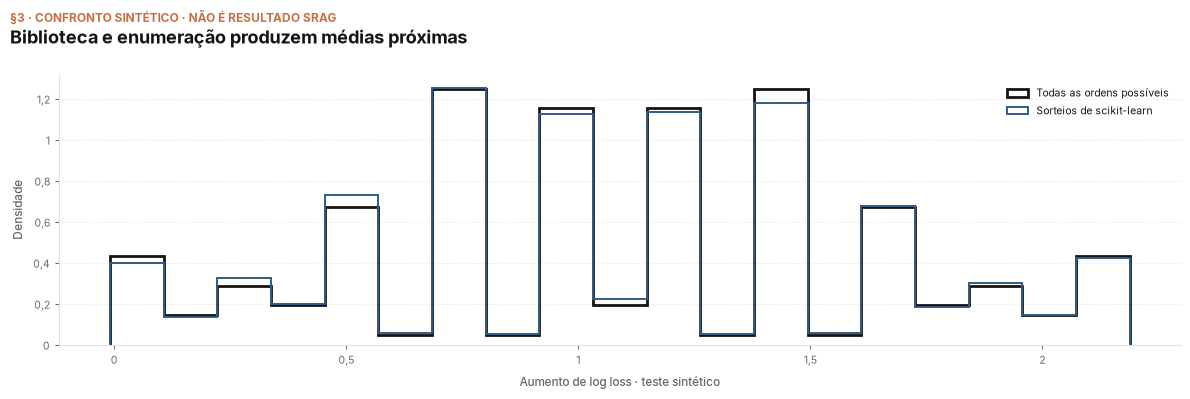

In [5]:
library_repeats = 6000
library = permutation_importance(
    model, x, y,
    scoring=lambda fitted, inputs, target: -log_loss(
        target, fitted.predict_proba(inputs)[:, 1]
    ),
    n_repeats=library_repeats,
    random_state=RANDOM_STATE,
)
library_delta = library.importances[0]
library_mcse = library_delta.std(ddof=1) / np.sqrt(library_repeats)
mean_gap = abs(library_delta.mean() - exact_delta.mean())
assert mean_gap < 4 * library_mcse
np.testing.assert_allclose(library.importances_mean[0], library_delta.mean(), rtol=0, atol=0)
np.testing.assert_allclose(library.importances_std[0], library_delta.std(ddof=0), rtol=0, atol=0)
converted_sd = library.importances_std[0] * np.sqrt(library_repeats / (library_repeats - 1))
np.testing.assert_allclose(converted_sd, library_delta.std(ddof=1), rtol=0, atol=1e-15)
print("Sorteios independentes de scikit-learn:", SP.pt_int(library_repeats))
print("PFI média sintética exata:", SP.pt(exact_delta.mean(), 8))
print("PFI média de scikit-learn:", SP.pt(library_delta.mean(), 8))
print("Diferença absoluta entre médias:", SP.pt(mean_gap, 8))
print("Erro Monte Carlo da média da biblioteca:", SP.pt(library_mcse, 8))
print("Critério de conferência:", SP.pt_int(4), "vezes esse erro; critério atendido.")
print("SD de scikit-learn, ddof =", SP.pt_int(0), ":", SP.pt(library.importances_std[0], 8))
print("SD amostral após conversão, ddof =", SP.pt_int(1), ":", SP.pt(converted_sd, 8))
print("Conversão de SD confere com os sorteios individuais.")

fig, ax = plt.subplots(figsize=SP.FAIXA)
bins = np.linspace(min(exact_delta.min(), library_delta.min()), max(exact_delta.max(), library_delta.max()), 20)
ax.hist(exact_delta, bins=bins, density=True, histtype="step", linewidth=2, color=SP.ESCURO, label="Todas as ordens possíveis")
ax.hist(library_delta, bins=bins, density=True, histtype="step", linewidth=1.4, color=SP.AZUL, label="Sorteios de scikit-learn")
ax.set_xlabel("Aumento de log loss · teste sintético")
ax.set_ylabel("Densidade")
ax.legend(frameon=False)
SP.titulo(fig, "Biblioteca e enumeração produzem médias próximas", "§3 · CONFRONTO SINTÉTICO · NÃO É RESULTADO SRAG")
SP.salvar(fig, "pfi-internals-library")
display(fig)
plt.close(fig)


**O que olhar.** As médias concordam dentro do critério de Monte Carlo declarado. A conversão de SD é exata; não seria correto comparar a SD amostral da aula diretamente com o campo `importances_std` da biblioteca.

## §4 — Invariantes que uma média correta não garante

Uma segunda matriz sintética mistura categorias nativas, campos booleanos e números. Conferimos índice, tipos, níveis e as colunas que ficam fixas. O embaralhamento conjunto deve preservar as tuplas observadas; o restrito a subgrupos deve conservar o agrupamento de cada registro.

Um preditor de auditoria rejeita chamadas de treinamento. Suas probabilidades saem em precisão simples; a perda registra o tipo que recebe para conferir a conversão do núcleo. Esse preditor foi construído apenas para o teste.


In [6]:
categories = ["desconhecido", "nao", "sim"]
cx = pd.DataFrame({
    "heart": pd.Categorical(["sim", "nao", "desconhecido", "nao", "sim", "desconhecido"], categories=categories),
    "diabetes": pd.Categorical(["sim", "nao", "sim", "desconhecido", "nao", "desconhecido"], categories=categories),
    "fixed_bool": [True, False, True, False, True, False],
    "fixed_number": np.arange(6, dtype=np.int32),
}, index=[91, 2, 18, 4, 52, 9])
cy = np.array([1, 0, 0, 1, 0, 1])
cx_snapshot = cx.copy(deep=True)
cy_snapshot = cy.copy()
order = np.array([2, 4, 0, 5, 1, 3])

single = E.permutar_colunas(cx, "heart", order)
np.testing.assert_array_equal(single["heart"].to_numpy(), cx["heart"].to_numpy()[order])
pd.testing.assert_frame_equal(single.drop(columns="heart"), cx.drop(columns="heart"))
assert single.index.equals(cx.index)
assert single.dtypes.equals(cx.dtypes)
assert single["heart"].cat.categories.equals(cx["heart"].cat.categories)

joint_order = np.array([5, 0, 4, 1, 3, 2])
joint = E.permutar_colunas(cx, ("heart", "diabetes"), joint_order)
for column in ["heart", "diabetes"]:
    np.testing.assert_array_equal(joint[column].to_numpy(), cx[column].to_numpy()[joint_order])
assert not joint["diabetes"].equals(cx["diabetes"])
original_pairs = cx.groupby(["heart", "diabetes"], observed=False).size()
joint_pairs = joint.groupby(["heart", "diabetes"], observed=False).size()
pd.testing.assert_series_equal(joint_pairs, original_pairs)
pd.testing.assert_frame_equal(joint.drop(columns=["heart", "diabetes"]), cx.drop(columns=["heart", "diabetes"]))
# This explicit donor order stays in each original diabetes group.
np.testing.assert_array_equal(cx["diabetes"].to_numpy()[order], cx["diabetes"].to_numpy())
within = E.permutar_colunas(cx, "heart", order)
pd.testing.assert_series_equal(within.groupby(["heart", "diabetes"], observed=False).size(), original_pairs)
pd.testing.assert_series_equal(within["diabetes"], cx["diabetes"])

class AuditPredictor:
    def __init__(self):
        self.fit_calls = 0
        self.prediction_calls = 0
    def fit(self, *args, **kwargs):
        self.fit_calls += 1
        raise AssertionError("PFI não deve chamar fit.")
    def predict_proba(self, inputs):
        self.prediction_calls += 1
        probability = inputs["heart"].map({"nao": .1, "sim": .8, "desconhecido": .4}).astype(float).to_numpy(dtype=np.float32)
        return np.column_stack([1 - probability, probability])

probability_types = []
def audit_loss(target, probability):
    probability_types.append(probability.dtype)
    return float(log_loss(target, probability))

audit_model = AuditPredictor()
cat_before, cat_after = E.trace_pfi(audit_model, cx, cy, "heart", [order, np.arange(len(cx))], audit_loss)
assert cat_after[-1] == cat_before
assert audit_model.fit_calls == 0
assert all(dtype == np.dtype("float64") for dtype in probability_types)
pd.testing.assert_frame_equal(cx, cx_snapshot)
np.testing.assert_array_equal(cy, cy_snapshot)
ignored_before, ignored_after = E.trace_pfi(audit_model, cx, cy, "fixed_number", [order, np.arange(len(cx))], audit_loss)
np.testing.assert_allclose(ignored_after, ignored_before, rtol=0, atol=0)
print("Tipos, níveis de categoria, índice e campos fixos: preservados.")
print("Tuplas preservadas no embaralhamento conjunto: verdadeiro.")
print("Subgrupos de diabetes preservados pela ordem restrita: verdadeiro.")
print("Mudança após restaurar a identidade:", SP.pt(cat_after[-1] - cat_before, 8))
print("Mudança da variável ignorada pelo preditor:", SP.pt(np.max(np.abs(ignored_after - ignored_before)), 8))
print("Chamadas de treinamento:", SP.pt_int(audit_model.fit_calls))
print("Todas as perdas receberam probabilidade float64:", all(dtype == np.dtype("float64") for dtype in probability_types))

invalid_cases = [
    ("heart", np.array([0, 0, 2, 3, 4, 5])),
    ("heart", np.array([0, 1, 2, 3, 4])),
    ("heart", np.array([0, 1, 2, 3, 4, 6])),
    ("heart", np.arange(len(cx), dtype=float)),
    ("missing", np.arange(len(cx))),
    (("heart", "heart"), np.arange(len(cx))),
    ((), np.arange(len(cx))),
]
rejected = 0
for columns, bad_order in invalid_cases:
    try:
        E.permutar_colunas(cx, columns, bad_order)
    except ValueError:
        rejected += 1
assert rejected == len(invalid_cases)
invalid_studies = [{"repeats": 0}, {"repeats": 1}, {"repeats": 2.5}, {"split": "train"}]
for kwargs in invalid_studies:
    try:
        P.study(WORK / "invalid-study", **kwargs)
    except ValueError:
        continue
    raise AssertionError("Contrato inválido deveria ser rejeitado antes do ajuste.")
print("Pedidos inválidos rejeitados pelo transporte:", SP.pt_int(rejected))
print("Pedidos inválidos rejeitados pelo estudo:", SP.pt_int(len(invalid_studies)))


Tipos, níveis de categoria, índice e campos fixos: preservados.
Tuplas preservadas no embaralhamento conjunto: verdadeiro.
Subgrupos de diabetes preservados pela ordem restrita: verdadeiro.
Mudança após restaurar a identidade: 0,00000000
Mudança da variável ignorada pelo preditor: 0,00000000
Chamadas de treinamento: 0
Todas as perdas receberam probabilidade float64: True
Pedidos inválidos rejeitados pelo transporte: 7
Pedidos inválidos rejeitados pelo estudo: 4


**O que olhar.** A variável ignorada não muda as probabilidades. Restaurar a identidade após um sorteio confirma que a perturbação não se acumula. O teste conjunto conserva os pares, enquanto o teste restrito conserva o grupo de cada destino; nenhum deles protege todas as relações com outras entradas.

## §5 — Conferir os registros reais que alimentam os slides

Agora lemos os resultados comprometidos de SRAG. Esta seção verifica integridade da amostra, ordens reproduzidas, sinais, médias, SD, erro Monte Carlo, ranks e equivalência entre diferença e razão. Não reexecuta o ajuste nem a busca de modelos. O walkthrough reconstrói o preditor e confere o traço real de idade.

A avaliação usa o modelo e o teste histórico fixos. A dispersão desses sorteios mede somente variação da permutação. O teste temporal já observado é exploratório.


In [7]:
gold_dir = REPO / "modules/00-dataset/gold"
record = json.loads((gold_dir / "pfi_ranking.json").read_text())
slides = json.loads((gold_dir / "pfi_slide_explainer.json").read_text())
protocol = record["protocol"]
assert protocol["repeats"] >= 2
assert protocol["split"] == "test"
sample_hash = hashlib.sha256((gold_dir / "gold_covid_obito_sample.parquet").read_bytes()).hexdigest()
assert sample_hash == protocol["sample_sha256"]
rng = np.random.default_rng(protocol["permutation_seed"])
record_orders = [rng.permutation(protocol["n_evaluation"]) for _ in range(protocol["repeats"])]
orders_hash = hashlib.sha256(np.asarray(record_orders).tobytes()).hexdigest()
assert orders_hash == protocol["permutation_orders_sha256"]
mean_discrepancies, sd_discrepancies = [], []
for row in record["rows"]:
    for metric, result in row["metrics"].items():
        after = np.asarray(result["after"])
        delta = np.asarray(result["delta"])
        direction = -1 if metric == "auc" else 1
        assert len(after) == protocol["repeats"]
        np.testing.assert_allclose(delta, direction * (after - record["original"][metric]), rtol=0, atol=1e-15)
        mean_discrepancies.append(abs(delta.mean() - result["mean"]))
        sd_discrepancies.append(abs(delta.std(ddof=1) - result["sd"]))
        np.testing.assert_allclose(result["after_mean"], after.mean(), rtol=0, atol=1e-15)
        np.testing.assert_allclose(result["after_sd"], after.std(ddof=1), rtol=0, atol=1e-15)
        np.testing.assert_allclose(result["mcse"], delta.std(ddof=1) / np.sqrt(len(delta)), rtol=0, atol=1e-15)
for metric in record["original"]:
    deltas = np.asarray([row["metrics"][metric]["delta"] for row in record["rows"]])
    ranks = pd.DataFrame(deltas).rank(ascending=False, method="average").to_numpy()
    rank_order = np.argsort(-deltas.mean(axis=1), kind="stable")
    for position, row_index in enumerate(rank_order):
        result = record["rows"][row_index]["metrics"][metric]
        assert result["rank"] == position + 1
        np.testing.assert_allclose(result["rank_repeats"], ranks[row_index], rtol=0, atol=0)
        np.testing.assert_allclose(result["rank_mean"], ranks[row_index].mean(), rtol=0, atol=1e-15)
        np.testing.assert_allclose(result["rank_sd"], ranks[row_index].std(ddof=1), rtol=0, atol=1e-15)
        assert result["top10_fraction"] == np.mean(ranks[row_index] <= 10)

import srag_72_pfi_presentation as Q
public = Q.project_aggregates(slides)
baseline = record["original"]["logloss"]
assert baseline > 0
for row in public["rows"]:
    canonical = next(r for r in record["rows"] if r["feature"] == row["feature"])["metrics"]["logloss"]
    assert row["before"] == baseline
    for slide_key, source_key in [("after_mean", "after_mean"), ("after_sd", "after_sd"), ("difference_mean", "mean"), ("difference_sd", "sd")]:
        np.testing.assert_allclose(row[slide_key], canonical[source_key], rtol=0, atol=1e-15)
    np.testing.assert_allclose(row["ratio_mean"], row["after_mean"] / baseline, rtol=0, atol=1e-15)
    np.testing.assert_allclose(row["ratio_sd"], row["difference_sd"] / baseline, rtol=0, atol=1e-15)
age = next(row for row in record["rows"] if row["feature"] == "idade_anos")["metrics"]["logloss"]
np.testing.assert_allclose(public["walkthrough"]["after"], age["after"], rtol=0, atol=0)
np.testing.assert_allclose(public["walkthrough"]["difference"], age["delta"], rtol=0, atol=0)
for diagnostic in public["dependence"]["results"]:
    after = np.asarray(diagnostic["after"])
    delta = np.asarray(diagnostic["difference"])
    assert len(after) == protocol["repeats"]
    np.testing.assert_allclose(delta, after - baseline, rtol=0, atol=1e-15)
    np.testing.assert_allclose(diagnostic["after_mean"], after.mean(), rtol=0, atol=1e-15)
    np.testing.assert_allclose(diagnostic["difference_mean"], delta.mean(), rtol=0, atol=1e-15)
    np.testing.assert_allclose(diagnostic["difference_sd"], delta.std(ddof=1), rtol=0, atol=1e-15)

print("SHA da amostra e SHA das ordens: conferem com o protocolo.")
print("Variáveis:", SP.pt_int(len(record["rows"])), "; métricas:", SP.pt_int(len(record["original"])), "; repetições:", SP.pt_int(protocol["repeats"]))
print("Ano do teste:", str(protocol["period"]), "; registros:", SP.pt_int(protocol["n_evaluation"]), "; óbitos:", SP.pt_int(protocol["events"]))
print("Semente registrada:", SP.pt_int(protocol["permutation_seed"]))
print("Maior discrepância de médias:", SP.pt(max(mean_discrepancies), 15))
print("Maior discrepância de SD:", SP.pt(max(sd_discrepancies), 15))
print("Resumos de gráficos conferidos:", SP.pt_int(len(public["rows"])))
print("Diagnósticos de dependência conferidos:", SP.pt_int(len(public["dependence"]["results"])))
print("Sinais e ranks conferidos para todas as métricas; traço de Age idêntico ao registro.")
print("Log loss original SRAG:", SP.pt(baseline, 8))
print("Idade, PFI média ± SD:", SP.pt(age["mean"], 8), "±", SP.pt(age["sd"], 8))


import copy
import srag_72_pfi_presentation as Q
public = Q.project_aggregates(slides)
Q.validate_aggregates(public)
assert "preview" not in public
assert set(public["dependence"]) == {"results", "protocol"}
assert Q.project_aggregates({**slides, "unselected_example": {"patient": "must not ship"}}) == public
injected = copy.deepcopy(public)
injected["study"]["patient_example"] = {"probability": 0.9}
try:
    Q.validate_aggregates(injected)
except ValueError:
    pass
else:
    raise AssertionError("An extra nested field escaped the public projection.")
misreported = copy.deepcopy(public)
misreported["rows"][0]["difference_mean"] += .01
try:
    Q.validate_aggregates(misreported)
except ValueError:
    pass
else:
    raise AssertionError("An inconsistent displayed measurement was accepted.")
print("Projeção pública: campos individuais não selecionados; injeção e número inconsistente rejeitados.")


SHA da amostra e SHA das ordens: conferem com o protocolo.
Variáveis: 40 ; métricas: 3 ; repetições: 50
Ano do teste: 2024 ; registros: 16.142 ; óbitos: 2.945
Semente registrada: 42
Maior discrepância de médias: 0,000000000000000
Maior discrepância de SD: 0,000000000000000
Resumos de gráficos conferidos: 10
Diagnósticos de dependência conferidos: 4
Sinais e ranks conferidos para todas as métricas; traço de Age idêntico ao registro.
Log loss original SRAG: 0,40901958
Idade, PFI média ± SD: 0,08463367 ± 0,00265889
Projeção pública: campos individuais não selecionados; injeção e número inconsistente rejeitados.


### A coerência da janela real do experimento global

Reconstruímos o preditor de SRAG e reproduzimos a primeira ordem global do
registro. Um transporte posicional independente preserva os tipos originais
e confere o erro de todo o teste, além das previsões das fichas receptoras
visíveis. Nenhum doador é selecionado pelo seu desfecho ou pela nova perda.
A ordem manual antiga e suas perdas ficam auditadas para registrar a correção.
A janela selecionada por desfecho não estima o desempenho global.


In [8]:
# Reproduzir o modelo e o recorte pela amostra comprometida, sem publicar índices.
case_gold = M.load_gold(gold_dir / "gold_covid_obito_sample.parquet")
case_design, _, case_design_target = M.design_matrix(case_gold)
case_train_mask = (case_gold["split"] == "train").to_numpy()
case_test_mask = (case_gold["split"] == "test").to_numpy()
srag_model = XGBClassifier(**protocol["xgb_params"]).fit(case_design.loc[case_train_mask],
                                                         case_design_target[case_train_mask])
srag_model_snapshot = bytes(srag_model.get_booster().save_raw())
case_test = case_gold.loc[case_test_mask]
historical_case = slides["preview"]
case_index = pd.concat([
    case_test[(case_test["idade_anos"] >= 18) & (case_test["y_obito"] == outcome)]
    .head(historical_case["selection"]["records_per_outcome"])
    for outcome in (0, 1)
]).sort_index().index
case_inputs = case_design.loc[case_index].reset_index(drop=True)
case_inputs_snapshot = case_inputs.copy(deep=True)
case_target = case_gold.loc[case_index, "y_obito"].to_numpy()
full_case_inputs = case_design.loc[case_test_mask].reset_index(drop=True)
full_case_target = case_design_target[case_test_mask]
case_positions = case_gold.loc[case_test_mask].index.get_indexer(case_index)
assert np.all(case_positions >= 0)
pd.testing.assert_frame_equal(full_case_inputs.iloc[case_positions].reset_index(drop=True), case_inputs)
case_payload = H.build_teaching_demo(srag_model, full_case_inputs, full_case_target,
                                     case_positions, historical_case, public["rows"], record)
case = case_payload["preview"]
case_top_fields = {"metric", "rows", "rounds", "permutation_seed", "displayed_repeat", "evaluation_n",
                   "permutation_scope", "permutation_orders_sha256", "threshold", "age_unit", "selection", "scope"}
case_row_fields = {"record", "idade_anos", "saturacao", "y_obito", "p_original",
                   "class_original", "correct_original", "loss_original",
                   "p_after_age", "class_after_age", "correct_after_age", "loss_after_age",
                   "p_after_oxygen", "class_after_oxygen", "correct_after_oxygen", "loss_after_oxygen"}
case_round_fields = {"feature", "label", "cell", "values", "shuffled_values", "probability", "predicted",
                     "correct", "individual_loss", "sample_loss_mean", "full_test_single_loss", "full_test"}
case_full_fields = {"feature", "label", "before", "after_mean", "after_sd", "difference_mean",
                    "difference_sd", "ratio_mean", "ratio_sd", "relative_increase_percent"}
assert set(case) == case_top_fields
assert set(case["selection"]) == {"records_per_outcome", "rule"}
assert [row["record"] for row in case["rows"]] == list("ABCDEFGH")
assert all(set(row) == case_row_fields for row in case["rows"])
assert all(set(round_) == case_round_fields for round_ in case["rounds"])
assert all(set(round_["full_test"]) == case_full_fields for round_ in case["rounds"])
assert case["age_unit"] == "decimal years at symptom onset"
case_target = np.asarray([row["y_obito"] for row in case["rows"]], dtype=int)
assert set(case_target) == {0, 1}
assert np.all(np.bincount(case_target) == case["selection"]["records_per_outcome"])
case_age = np.asarray([row["idade_anos"] for row in case["rows"]], dtype=np.float64)
assert np.all(case_age >= 18)
np.testing.assert_array_equal(case_age.astype(np.float32).astype(np.float64), case_age)
global_order = record_orders[0]
assert case["permutation_seed"] == protocol["permutation_seed"]
assert case["displayed_repeat"] == 1
assert case["evaluation_n"] == len(full_case_inputs)
assert case["permutation_scope"] == "full temporal test"
assert case["permutation_orders_sha256"] == orders_hash
case_original = np.asarray([row["p_original"] for row in case["rows"]], dtype=np.float64)
np.testing.assert_array_equal(case_original, [row["p_original"] for row in historical_case["rows"]])
case_threshold = float(case["threshold"])
assert 0 < case_threshold < 1
assert np.all((case_original >= 0) & (case_original <= 1))
case_original_class = (case_original >= case_threshold).astype(int)
case_original_loss = np.where(case_target == 1, -np.log(case_original), -np.log1p(-case_original))
np.testing.assert_array_equal(case_original_class, [row["class_original"] for row in case["rows"]])
np.testing.assert_array_equal(case_original_class == case_target, [row["correct_original"] for row in case["rows"]])
np.testing.assert_array_equal(case_original_loss, [row["loss_original"] for row in case["rows"]])
case_target_snapshot = case_target.copy()
case_checks = [{"estado": "Original", "Log loss do recorte": float(case_original_loss.mean()),
                "erros de classe": int(np.count_nonzero(case_original_class != case_target)),
                "valores alterados": 0, "probabilidades alteradas": 0}]
assert [(r["feature"], r["cell"]) for r in case["rounds"]] == [("idade_anos", "age"), ("saturacao", "oxygen")]
for round_ in case["rounds"]:
    feature, cell = round_["feature"], round_["cell"]
    original_values = case_inputs[feature].to_numpy()
    np.testing.assert_array_equal(original_values, round_["values"])
    # Oráculo: transporta o array do TESTE INTEIRO, sem chamar permutar_colunas.
    full_moved_values = full_case_inputs[feature].to_numpy()[global_order]
    moved_values = full_moved_values[case_positions]
    np.testing.assert_array_equal(moved_values, round_["shuffled_values"])
    independent_inputs = full_case_inputs.copy(deep=True)
    if isinstance(full_case_inputs[feature].dtype, pd.CategoricalDtype):
        independent_inputs[feature] = pd.Categorical(full_moved_values,
            categories=full_case_inputs[feature].cat.categories,
            ordered=full_case_inputs[feature].cat.ordered)
    else:
        independent_inputs[feature] = full_moved_values
    assert independent_inputs.dtypes.equals(full_case_inputs.dtypes)
    pd.testing.assert_frame_equal(independent_inputs.drop(columns=feature), full_case_inputs.drop(columns=feature))
    independent_full_probability = np.asarray(srag_model.predict_proba(independent_inputs)[:, 1], dtype=np.float64)
    independent_full_loss = np.where(full_case_target == 1, -np.log(independent_full_probability), -np.log1p(-independent_full_probability))
    registered_single = next(r for r in record["rows"] if r["feature"] == feature)["metrics"]["logloss"]["after"][0]
    np.testing.assert_allclose(independent_full_loss.mean(), registered_single, rtol=0, atol=1e-15)
    np.testing.assert_allclose(round_["full_test_single_loss"], registered_single, rtol=0, atol=1e-15)
    probabilities = np.asarray(round_["probability"], dtype=np.float64)
    np.testing.assert_array_equal(probabilities, independent_full_probability[case_positions])
    assert len(probabilities) == len(case_target)
    assert np.all((probabilities >= 0) & (probabilities <= 1))
    classes = (probabilities >= case_threshold).astype(int)
    correct = classes == case_target
    losses = np.where(case_target == 1, -np.log(probabilities), -np.log1p(-probabilities))
    for values, key, round_key in [(probabilities, "p", "probability"),
                                    (classes, "class", "predicted"),
                                    (correct, "correct", "correct"),
                                    (losses, "loss", "individual_loss")]:
        np.testing.assert_array_equal(values, round_[round_key])
        np.testing.assert_array_equal(values, [row[key + "_after_" + cell] for row in case["rows"]])
    np.testing.assert_allclose(losses.mean(), round_["sample_loss_mean"], rtol=0, atol=1e-15)
    canonical = next(row for row in public["rows"] if row["feature"] == feature)
    assert round_["full_test"] == canonical
    np.testing.assert_array_equal(case_target, case_target_snapshot)
    case_checks.append({
        "estado": round_["label"] + " permutada", "Log loss do recorte": float(losses.mean()),
        "erros de classe": int(np.count_nonzero(~correct)),
        "valores alterados": int(np.count_nonzero(moved_values != original_values)),
        "probabilidades alteradas": int(np.count_nonzero(probabilities != case_original)),
    })
case_checks = pd.DataFrame(case_checks)
case_checks["diferença no recorte"] = case_checks["Log loss do recorte"] - case_original_loss.mean()
case_checks["razão no recorte"] = case_checks["Log loss do recorte"] / case_original_loss.mean()
case_checks["variação relativa percentual"] = (case_checks["razão no recorte"] - 1) * 100
pd.testing.assert_frame_equal(case_inputs, case_inputs_snapshot)
np.testing.assert_array_equal(case_target, case_target_snapshot)
assert bytes(srag_model.get_booster().save_raw()) == srag_model_snapshot
assert "preview" not in public
Q.validate_aggregates(public)
print("Recorte: campos fechados e rótulos A–H; sem identificadores, índices, datas ou localidade:", True)
print("Fichas conferidas:", SP.pt_int(len(case_target)), "; estados:", SP.pt_int(len(case_checks)))
print("Probabilidades individuais conferidas:", SP.pt_int(len(case_target) * len(case_checks)))
print("Limiar:", SP.pt(case_threshold, 2), "; idades preservadas em float32:", True)
print("Semente global:", SP.pt_int(case["permutation_seed"]), "; repetição visível:", SP.pt_int(case["displayed_repeat"]))
print("Registros na permutação global:", SP.pt_int(case["evaluation_n"]), "; hash das ordens confere:", case["permutation_orders_sha256"] == orders_hash)
print("Doadores pertencem ao teste inteiro; índices, posições e desfechos doadores não são exportados.")
print("Alvos preservados e cada rodada parte das entradas originais:", True)
print(SP.tabela(case_checks, casas=8))
print("A janela usa agora uma repetição global real; fichas, previsões originais e PFI global não mudaram.")
print("Projeção pública agregada continua sem preview:", "preview" not in public)

# O contrato do exportador deve rejeitar estes erros, não apenas a cópia atual.
corrected_source = {**slides, "preview": case}
assert Q.project_teaching_records(corrected_source) == case_payload
assert case_payload["preview"] == case
Q.validate_teaching_records(case_payload, public)
case_rejections = []
for corruption in ("Identificador extra", "Repetição divergente", "Semente divergente",
                   "Coluna visual errada", "Contexto global divergente", "Valor global divergente"):
    altered = copy.deepcopy(case_payload)
    if corruption == "Identificador extra":
        altered["preview"]["rows"][0]["gold_id"] = "must not ship"
    elif corruption == "Repetição divergente":
        altered["preview"]["displayed_repeat"] += 1
    elif corruption == "Semente divergente":
        altered["preview"]["permutation_seed"] += 1
    elif corruption == "Coluna visual errada":
        altered["preview"]["rounds"][1]["cell"] = "age"
    elif corruption == "Contexto global divergente":
        altered["preview"]["rounds"][0]["full_test"]["after_mean"] += .01
    else:
        altered["preview"]["rounds"][0]["full_test_single_loss"] = -1
    try:
        Q.validate_teaching_records(altered, public)
    except ValueError:
        case_rejections.append({"corrupção": corruption, "resultado": "rejeitada"})
    else:
        raise AssertionError("A corrupted teaching projection passed its export contract.")
assert case_payload == Q.project_teaching_records(corrected_source)
print("Recorte válido aceito; corrupções rejeitadas pelo contrato independente do exportador:")
print(SP.tabela(pd.DataFrame(case_rejections)))


# Preservar e auditar o histórico: a álgebra era correta; a ordem manual restringia os doadores.
historical_order = np.asarray(historical_case["permutation"], dtype=int)
assert np.array_equal(case_target[historical_order], case_target)
historical_checks = []
for round_ in historical_case["rounds"]:
    historical_probability = np.asarray(round_["probability"], dtype=np.float64)
    historical_losses = (historical_probability - case_target) ** 2
    np.testing.assert_array_equal(historical_losses, round_["individual_brier"])
    np.testing.assert_allclose(historical_losses.mean(), round_["sample_brier_mean"], rtol=0, atol=1e-15)
    historical_checks.append({"estado histórico": round_["label"],
                               "Brier histórico": float(historical_losses.mean())})
print("Auditoria da ordem histórica preservada:", historical_order.tolist())
print("Trocas históricas entre desfechos distintos:", SP.pt_int(np.count_nonzero(case_target[historical_order] != case_target)))
print(SP.tabela(pd.DataFrame(historical_checks), casas=8))
case_output = WORK / "figures_generated/pfi-teaching-records.json"
case_output.parent.mkdir(exist_ok=True)
case_output.write_text(json.dumps(case_payload, ensure_ascii=False, indent=2) + "\n")
print("Arquivo recalculado independentemente:", case_output.name)
print("Primeira repetição global e resumos globais inalterados:")
print(SP.tabela(pd.DataFrame([{
    "entrada": r["label"], "original global": r["full_test"]["before"],
    "primeira repetição global": r["full_test_single_loss"],
    "média global": r["full_test"]["after_mean"], "SD global": r["full_test"]["after_sd"],
    "diferença global": r["full_test"]["difference_mean"],
    "aumento relativo global percentual": r["full_test"]["relative_increase_percent"],
} for r in case["rounds"]]), casas=8))


Recorte: campos fechados e rótulos A–H; sem identificadores, índices, datas ou localidade: True
Fichas conferidas: 8 ; estados: 3
Probabilidades individuais conferidas: 24
Limiar: 0,50 ; idades preservadas em float32: True
Semente global: 42 ; repetição visível: 1
Registros na permutação global: 16.142 ; hash das ordens confere: True
Doadores pertencem ao teste inteiro; índices, posições e desfechos doadores não são exportados.
Alvos preservados e cada rodada parte das entradas originais: True
              estado Log loss do recorte erros de classe valores alterados probabilidades alteradas diferença no recorte razão no recorte variação relativa percentual
            Original          0,89476575               4                 0                        0           0,00000000       1,00000000                   0,00000000
       Age permutada          0,87046091               4                 8                        8          -0,02430484       0,97283664                  -2,71633608


**O que olhar.** O confronto com os registros reais detecta divergência entre o que o estudo salvou e o que os slides mostram. Hashes conferem proveniência; não são um teste de qualidade clínica. Ambos os cadernos reproduzem o ajuste e o novo recorte; o transporte posicional e a álgebra são conferidos por um caminho independente.

## §6 — O que o livro diz

**O que o livro diz.** Molnar define a importância pela mudança de perda de um modelo fixo ao permutar uma entrada. O diagnóstico depende da perda, do modelo e dos dados de avaliação. Repetir sorteios descreve sua variabilidade, sem incorporar sozinho a incerteza de novos pacientes ou de novos treinamentos.

Os testes confirmam a operação marginal e o transporte conjunto. O exemplo de subgrupos conserva a categoria de diabetes, mas pode romper outras relações. Não é PFI condicional dado todo o restante. A importância conjunta não é, por definição, a soma das importâncias individuais; comparar esses números isoladamente não demonstra interação, redundância ou causalidade.


In [9]:
assert max(mean_discrepancies) < 1e-15
assert max(sd_discrepancies) < 1e-15
checks = pd.DataFrame([
    {"confronto": "Núcleo × oráculo posicional independente", "resultado": "passou"},
    {"confronto": "Distribuição exata × scikit-learn", "resultado": "passou no critério Monte Carlo"},
    {"confronto": "SD populacional × SD amostral", "resultado": "conversão conferida"},
    {"confronto": "Categorias, pares, grupos, alvos e ausência de fit", "resultado": "preservados"},
    {"confronto": "Registros reais × resumos da aula", "resultado": "conferem em precisão completa"},
])
print(SP.tabela(checks))


                                         confronto                      resultado
          Núcleo × oráculo posicional independente                         passou
                 Distribuição exata × scikit-learn passou no critério Monte Carlo
                     SD populacional × SD amostral            conversão conferida
Categorias, pares, grupos, alvos e ausência de fit                    preservados
                 Registros reais × resumos da aula  conferem em precisão completa


## §7 — Diabetes: PFI livre e por grupos de cardiopatia nas mesmas fichas

A prévia de frequências mostrou o transporte das respostas. Agora calculamos
sua consequência no erro do mesmo XGBoost histórico reconstruído na seção
anterior. Esta seção não treina novamente o modelo nem usa o estudo de seleção
mais recente. Restringimos o teste aos registros com cardiopatia e diabetes em
Sim/Não, preservando todas as entradas e o desfecho nos mesmos receptores.

O recorte tem seu próprio erro original. Repetimos a permutação livre de
somente diabetes e a permutação dentro dos grupos originais de cardiopatia,
sempre partindo das entradas originais. As ordens são pareadas entre os dois
procedimentos. A primeira reproduz a prévia registrada na §20 do caderno de
ranking; as demais seguem consecutivamente o mesmo gerador declarado.

Comparamos a perda no conjunto do recorte e nos seus grupos. As médias de
perda e suas diferenças agregam com pesos proporcionais aos tamanhos dos
grupos. A razão global é calculada diretamente com a perda e o baseline do
recorte, e não pela média simples das razões dos grupos. SD descreve apenas
a variabilidade dos sorteios com pacientes e modelo fixos.


Fonte: modules/00-dataset/gold/gold_covid_obito_sample.parquet
source_sha256: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
reference_protocol_sha256: 2ae2d067bb744f69202b8c8724f2ffcd083e84198e171df7e0cfdbb553b7de1e
model_raw_sha256: 55b1c49045b8b6368d61eb91073beaaf6197c0081613ad688670eaefe5e91007
first_order_sha256: ac344792347515a59421ed0cfae138d95899e3a1c04dbc128aee1ea5a4cf9e54
all_orders_sha256: ece8b66dc7a72841fcc82ad3dfdaa5f4dd96aab3c9244d48fd489901033a37df
first_within_order_sha256: b2efcf96d0b4a546c0f0b296db648a9e6f9595b7f513310dd79459a0375643e6
all_within_orders_sha256: 60b44518f50b4b49057427f465668f1674ce4ce31bc30d1c23842121bb4aed95
n_train: 200.000
n_full_test: 16.142
n_cohort: 7.762
n_excluded: 8.380
seed: 42
repeats: 50
sd_ddof: 1
Ano: 2024 ; entradas: 40
Parâmetros do preditor já ajustado:
n_estimators max_depth learning_rate min_child_weight reg_lambda tree_method  enable_categorical eval_metric random_state n_jobs
         800         4    0,05000000 

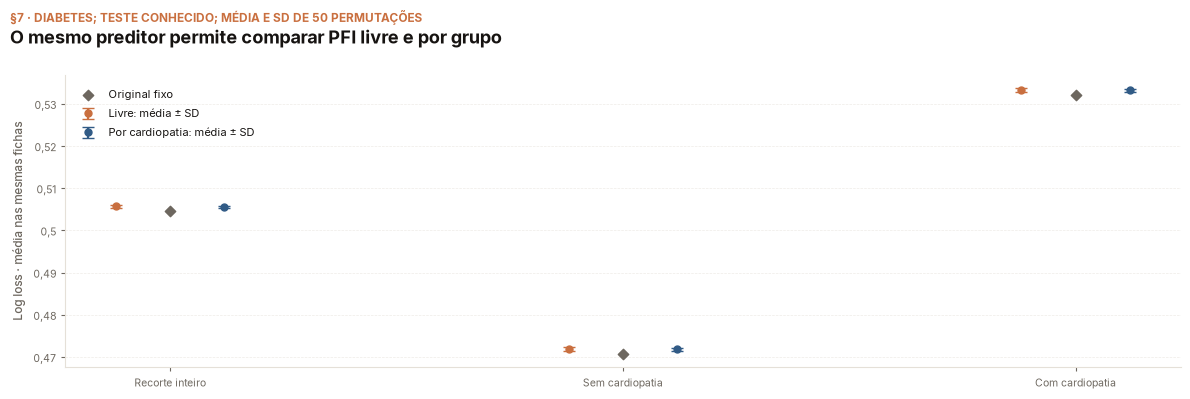

In [10]:
# Reuse the historical predictor already reconstructed in section 5.
from sklearn.metrics import brier_score_loss, roc_auc_score

pfi_sub_source = gold_dir / "gold_covid_obito_sample.parquet"
pfi_sub_source_hash = hashlib.sha256(pfi_sub_source.read_bytes()).hexdigest()
assert pfi_sub_source_hash == protocol["sample_sha256"]
assert protocol["xgb_params"] == M.XGB_PARAMS
assert int(case_train_mask.sum()) == protocol["n_train"]
assert list(full_case_inputs.columns) == list(M.FEATURES)
assert len(full_case_inputs.columns) == 40
assert np.array_equal(srag_model.classes_, [0, 1])
assert case_gold.loc[case_test_mask, "ano_onset"].eq(2024).all()
pfi_sub_model_raw = bytes(srag_model.get_booster().save_raw(raw_format="ubj"))
assert pfi_sub_model_raw == srag_model_snapshot
pfi_sub_model_hash = hashlib.sha256(pfi_sub_model_raw).hexdigest()
(WORK / "reference.ubj").write_bytes(pfi_sub_model_raw)
pfi_sub_protocol_hash = hashlib.sha256(json.dumps(protocol, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()).hexdigest()
full_probability = np.asarray(srag_model.predict_proba(full_case_inputs)[:, 1], dtype=np.float64)
pfi_sub_full_metrics = {
    "logloss": float(log_loss(full_case_target, full_probability, labels=[0, 1])),
    "brier": float(brier_score_loss(full_case_target, full_probability)),
    "auc": float(roc_auc_score(full_case_target, full_probability)),
}
for key, value in pfi_sub_full_metrics.items():
    np.testing.assert_allclose(value, record["original"][key], rtol=0, atol=1e-12)

sub_mask = (full_case_inputs["cardiopati"].isin(["nao", "sim"]) & full_case_inputs["diabetes"].isin(["nao", "sim"])).to_numpy()
sub_inputs = full_case_inputs.loc[sub_mask].reset_index(drop=True)
sub_target = np.asarray(full_case_target)[sub_mask].copy()
sub_snapshot, sub_target_snapshot = sub_inputs.copy(deep=True), sub_target.copy()
sub_levels = ["nao", "sim"]
sub_cardio = sub_inputs["cardiopati"].to_numpy(copy=True)
sub_diabetes = sub_inputs["diabetes"].to_numpy(copy=True)
sub_groups = {level: sub_cardio == level for level in sub_levels}
sub_n, sub_seed, sub_repeats = len(sub_inputs), 42, 50
sub_weights = {level: float(mask.sum() / sub_n) for level, mask in sub_groups.items()}
sub_rng = np.random.default_rng(sub_seed)
sub_orders = [sub_rng.permutation(sub_n) for _ in range(sub_repeats)]
assert hashlib.sha256(sub_orders[0].tobytes()).hexdigest() == "ac344792347515a59421ed0cfae138d95899e3a1c04dbc128aee1ea5a4cf9e54"
sub_restricted = []
for order in sub_orders:
    restricted = np.arange(sub_n, dtype=order.dtype)
    for level, mask in sub_groups.items():
        restricted[np.flatnonzero(mask)] = order[sub_cardio[order] == level]
    assert np.array_equal(sub_cardio[restricted], sub_cardio)
    assert np.array_equal(np.sort(restricted), np.arange(sub_n))
    sub_restricted.append(restricted)
assert hashlib.sha256(sub_restricted[0].tobytes()).hexdigest() == "b2efcf96d0b4a546c0f0b296db648a9e6f9595b7f513310dd79459a0375643e6"


def sub_individual_loss(target, probability):
    clipped = np.clip(np.asarray(probability, dtype=np.float64), np.finfo(np.float64).eps, 1 - np.finfo(np.float64).eps)
    return np.where(np.asarray(target) == 1, -np.log(clipped), -np.log1p(-clipped))


sub_original_probability = full_probability[sub_mask]
sub_original_individual = sub_individual_loss(sub_target, sub_original_probability)
sub_baseline = float(log_loss(sub_target, sub_original_probability, labels=[0, 1]))
np.testing.assert_allclose(sub_baseline, sub_original_individual.mean(), rtol=0, atol=1e-15)
sub_baselines = {level: float(log_loss(sub_target[mask], sub_original_probability[mask], labels=[0, 1])) for level, mask in sub_groups.items()}
np.testing.assert_allclose(sub_baseline, sum(sub_weights[level] * sub_baselines[level] for level in sub_levels), rtol=0, atol=1e-15)
sub_losses = {scope: {mode: [] for mode in ["marginal", "within"]} for scope in ["global"] + sub_levels}
sub_max_manual_gap, sub_max_weight_gap, sub_max_delta_weight_gap = 0.0, 0.0, 0.0
for mode, orders in [("marginal", sub_orders), ("within", sub_restricted)]:
    for order in orders:
        perturbed = E.permutar_colunas(sub_inputs, "diabetes", order)
        pd.testing.assert_frame_equal(perturbed.drop(columns="diabetes"), sub_inputs.drop(columns="diabetes"))
        assert perturbed.dtypes.equals(sub_inputs.dtypes)
        np.testing.assert_array_equal(perturbed["diabetes"].to_numpy(), sub_diabetes[order])
        probability = np.asarray(srag_model.predict_proba(perturbed)[:, 1], dtype=np.float64)
        individual = sub_individual_loss(sub_target, probability)
        loss = float(log_loss(sub_target, probability, labels=[0, 1]))
        sub_max_manual_gap = max(sub_max_manual_gap, abs(loss - float(individual.mean())))
        np.testing.assert_allclose(loss, individual.mean(), rtol=0, atol=1e-15)
        sub_losses["global"][mode].append(loss)
        for level, mask in sub_groups.items():
            group_loss = float(log_loss(sub_target[mask], probability[mask], labels=[0, 1]))
            np.testing.assert_allclose(group_loss, individual[mask].mean(), rtol=0, atol=1e-15)
            sub_losses[level][mode].append(group_loss)
        weighted_loss = sum(sub_weights[level] * sub_losses[level][mode][-1] for level in sub_levels)
        weighted_delta = sum(sub_weights[level] * (sub_losses[level][mode][-1] - sub_baselines[level]) for level in sub_levels)
        sub_max_weight_gap = max(sub_max_weight_gap, abs(loss - weighted_loss))
        sub_max_delta_weight_gap = max(sub_max_delta_weight_gap, abs((loss - sub_baseline) - weighted_delta))
        np.testing.assert_allclose(loss, weighted_loss, rtol=0, atol=1e-15)
        np.testing.assert_allclose(loss - sub_baseline, weighted_delta, rtol=0, atol=1e-15)
        pd.testing.assert_frame_equal(sub_inputs, sub_snapshot)
        np.testing.assert_array_equal(sub_target, sub_target_snapshot)
assert bytes(srag_model.get_booster().save_raw(raw_format="ubj")) == pfi_sub_model_raw


def sub_summary(values, before):
    after = np.asarray(values, dtype=np.float64)
    difference = after - before
    ratio = after / before
    relative = (ratio - 1) * 100
    result = {"after": after.tolist(), "difference": difference.tolist(), "ratio": ratio.tolist(), "relative_percent": relative.tolist()}
    for key, values in [("after", after), ("difference", difference), ("ratio", ratio), ("relative_percent", relative)]:
        result[key + "_mean"] = float(values.mean())
        result[key + "_sd"] = float(values.std(ddof=1))
        result["first_" + key] = float(values[0])
    return result


pfi_sub_rules = {
    "model": "Mesmo XGBoost histórico já reconstruído uma vez na seção 5; nenhum ajuste nesta seção e nenhum uso do estudo course-v2.",
    "cohort": "Mesmo recorte fechado da prévia: cardiopati e diabetes em sim/nao no teste temporal, com todas as entradas originais e desfechos alinhados.",
    "baseline": "O recorte e cada grupo têm seu próprio log loss original; o baseline do teste inteiro serve somente à verificação da referência.",
    "marginal": "Permutar somente diabetes entre todos os receptores deste recorte; uma nova cópia das entradas originais em cada repetição.",
    "within": "Restaurar as entradas originais; filtrar cada ordem pelos grupos originais de cardiopatia, sem usar o desfecho como grupo.",
    "loss": "Log loss com probabilidades float64 e labels=[0,1]; também conferida pela média das perdas individuais, com clipping em epsilon float64.",
    "aggregation": "Loss e diferença globais são conferidas com pesos n/N das perdas dos grupos em cada repetição. A razão global é calculada diretamente como loss global / baseline global, não como média das razões dos grupos.",
    "sd": "SD amostral entre permutações, ddof=1; modelo e pacientes fixos. Não é intervalo de confiança nem incerteza de novos pacientes ou novos ajustes.",
    "relative_percent": "(razão do erro - 1) vezes 100; não é mudança de probabilidade de óbito nem percentual de classificações incorretas.",
    "degenerate": "Agrupar pelo próprio diabetes e embaralhar diabetes dentro desses grupos conservaria seus valores por construção; a PFI seria nula por essa operação degenerada. Nenhum experimento adicional desse tipo foi executado.",
    "interpretation": "A importância por subgrupos responde outra pergunta e pode ainda romper relações com outras entradas. Não é PFI condicional dado todo o restante, nem demonstra causa ou redundância.",
}
pfi_sub_payload = {
    "schema_version": "srag-diabetes-subgroup-pfi-v1",
    "metadata": {
        "source_path": "modules/00-dataset/gold/gold_covid_obito_sample.parquet", "source_sha256": pfi_sub_source_hash,
        "source_notebook": "modules/06-pfi/notebooks/pfi_internals.ipynb", "source_section": "§7",
        "reference_protocol_path": "modules/00-dataset/gold/pfi_ranking.json", "reference_protocol_sha256": pfi_sub_protocol_hash,
        "protocol_hash_encoding": "SHA256 of protocol object serialized as sorted-key compact UTF-8 JSON",
        "model_raw_sha256": pfi_sub_model_hash, "model_raw_format": "ubj", "xgb_params": dict(protocol["xgb_params"]),
        "n_train": int(case_train_mask.sum()), "n_full_test": len(full_case_inputs), "n_cohort": sub_n,
        "n_excluded": len(full_case_inputs) - sub_n, "year": 2024, "split": "test", "metric": "log_loss",
        "feature": "diabetes", "fixed_group_feature": "cardiopati", "seed": sub_seed, "repeats": sub_repeats, "sd_ddof": 1,
        "sampling": "none after known-pair restriction", "first_order_sha256": hashlib.sha256(sub_orders[0].tobytes()).hexdigest(),
        "all_orders_sha256": hashlib.sha256(np.asarray(sub_orders).tobytes()).hexdigest(),
        "first_within_order_sha256": hashlib.sha256(sub_restricted[0].tobytes()).hexdigest(),
        "all_within_orders_sha256": hashlib.sha256(np.asarray(sub_restricted).tobytes()).hexdigest(),
    },
    "full_test_reference": {key: {"reconstructed": value, "registered": float(record["original"][key])} for key, value in pfi_sub_full_metrics.items()},
    "rules": pfi_sub_rules,
    "results": {"global": {"n": sub_n, "events": int(sub_target.sum()), "baseline": sub_baseline, "baseline_sd": 0.0,
        **{mode: sub_summary(sub_losses["global"][mode], sub_baseline) for mode in ["marginal", "within"]}}, "groups": []},
}
for level, mask in sub_groups.items():
    pfi_sub_payload["results"]["groups"].append({"cardio": level, "n": int(mask.sum()), "weight": sub_weights[level],
        "events": int(sub_target[mask].sum()), "baseline": sub_baselines[level], "baseline_sd": 0.0,
        **{mode: sub_summary(sub_losses[level][mode], sub_baselines[level]) for mode in ["marginal", "within"]}})

# Regenerate the first-repeat input diagram without reading a local artifact.
sub_plot = {
    "x": {"key": "diabetes", "label": "Diabetes", "levels": sub_levels, "level_labels": {"nao": "Não", "sim": "Sim"}},
    "y": {"key": "cardiopati", "label": "Cardiopatia", "levels": sub_levels, "level_labels": {"nao": "Não", "sim": "Sim"}},
    "states": {}, "within_flows": {"levels": sub_levels, "level_labels": {"nao": "Não", "sim": "Sim"},
        "counts_orientation": "rows = original diabetes; columns = within-group diabetes", "groups": []},
    "source_procedure": "modules/00-dataset/notebooks/srag_pfi_ranking.ipynb §20; same closed cohort and first orders",
}
for mode, values in [("original", sub_diabetes), ("marginal", sub_diabetes[sub_orders[0]]), ("within", sub_diabetes[sub_restricted[0]])]:
    counts = pd.crosstab(sub_cardio, values).reindex(index=sub_levels, columns=sub_levels, fill_value=0).to_numpy(dtype=int)
    rows, columns = counts.sum(axis=1), counts.sum(axis=0)
    a, b, c, d = counts.astype(float).flat
    phi = float((a * d - b * c) / np.sqrt(np.prod(rows.astype(float)) * np.prod(columns.astype(float))))
    sub_plot["states"][mode] = {"counts": counts.tolist(), "n": sub_n, "phi": phi,
        "changed_n": int(np.count_nonzero(values != sub_diabetes)), "x_marginals": columns.tolist(), "y_marginals": rows.tolist(),
        "conditional": (counts / rows[:, None]).tolist(), "conditional_percent": (100 * (counts / rows[:, None])).tolist()}
for level, mask in sub_groups.items():
    counts = pd.crosstab(sub_diabetes[mask], sub_diabetes[sub_restricted[0]][mask]).reindex(index=sub_levels, columns=sub_levels, fill_value=0).to_numpy(dtype=int)
    sub_plot["within_flows"]["groups"].append({"cardio": level, "n": int(mask.sum()), "counts": counts.tolist(),
        "changed_n": int(counts[0, 1] + counts[1, 0]), "unchanged_n": int(np.trace(counts)),
        "no_to_yes_n": int(counts[0, 1]), "yes_to_no_n": int(counts[1, 0])})
assert sub_plot["states"]["original"]["counts"] == [[2674, 818], [2248, 2022]]
assert sub_plot["states"]["marginal"]["counts"] == [[2185, 1307], [2737, 1533]]
assert sub_plot["states"]["within"]["counts"] == sub_plot["states"]["original"]["counts"]
assert [group["counts"] for group in sub_plot["within_flows"]["groups"]] == [[[2050, 624], [624, 194]], [[1175, 1073], [1073, 949]]]
pfi_sub_payload["plot"] = sub_plot
pfi_sub_payload["checks"] = {"manual_loss_max_gap": sub_max_manual_gap, "weighted_loss_max_gap": sub_max_weight_gap,
    "weighted_difference_max_gap": sub_max_delta_weight_gap, "model_raw_unchanged": True, "original_inputs_unchanged": True,
    "target_unchanged": True, "other_39_inputs_unchanged_each_repeat": True, "first_diagram_matches_section20": True}

print("Fonte:", pfi_sub_payload["metadata"]["source_path"])
for key in ["source_sha256", "reference_protocol_sha256", "model_raw_sha256", "first_order_sha256", "all_orders_sha256", "first_within_order_sha256", "all_within_orders_sha256"]:
    print(key + ":", pfi_sub_payload["metadata"][key])
for key in ["n_train", "n_full_test", "n_cohort", "n_excluded", "seed", "repeats", "sd_ddof"]:
    print(key + ":", SP.pt_int(pfi_sub_payload["metadata"][key]))
print("Ano:", str(pfi_sub_payload["metadata"]["year"]), "; entradas:", SP.pt_int(len(sub_inputs.columns)))
print("Parâmetros do preditor já ajustado:")
print(SP.tabela(pd.DataFrame([protocol["xgb_params"]]), casas=8))
print("Métricas do teste inteiro versus registro histórico:")
print(SP.tabela(pd.DataFrame([{"métrica": key, **values} for key, values in pfi_sub_payload["full_test_reference"].items()]), casas=15))
for key, rule in pfi_sub_rules.items():
    print(key + ":", rule)
sub_scopes = [("global", pfi_sub_payload["results"]["global"])] + [(item["cardio"], item) for item in pfi_sub_payload["results"]["groups"]]
print("Baseline e composição dos recortes:")
print(SP.tabela(pd.DataFrame([{"recorte": name, "N": scope["n"], "óbitos": scope["events"], "peso n/N": scope.get("weight", 1.0),
    "log loss original": scope["baseline"], "SD original entre sorteios": scope["baseline_sd"]} for name, scope in sub_scopes]), casas=8))
sub_summary_print, sub_repeat_print = [], []
for name, scope in sub_scopes:
    for mode in ["marginal", "within"]:
        result = scope[mode]
        sub_summary_print.append({"recorte": name, "método": mode, **{key: value for key, value in result.items() if not isinstance(value, list)}})
        for index in range(sub_repeats):
            sub_repeat_print.append({"recorte": name, "método": mode, "repetição": index + 1,
                "after": result["after"][index], "difference": result["difference"][index],
                "ratio": result["ratio"][index], "relative_percent": result["relative_percent"][index]})
print("Primeira repetição e resumos das repetições; SD amostral:")
print(SP.tabela(pd.DataFrame(sub_summary_print), casas=10))
print("Todas as perdas, diferenças, razões e variações relativas percentuais por repetição:")
print(SP.tabela(pd.DataFrame(sub_repeat_print), casas=10))
for mode, values in sub_plot["states"].items():
    print("Diagrama da primeira repetição:", mode, "; phi:", SP.pt(values["phi"], 8), "; diabetes alterado:", SP.pt_int(values["changed_n"]))
    print(SP.tabela(pd.DataFrame(values["counts"], index=sub_levels, columns=sub_levels).reset_index(names="cardiopatia / diabetes"), casas=0))
    print(SP.tabela(pd.DataFrame([{"cardio": group, "diabetes": value, "proporção": values["conditional"][row][col],
        "percentual": values["conditional_percent"][row][col]} for row, group in enumerate(sub_levels) for col, value in enumerate(sub_levels)]), casas=8))
    print("Marginais diabetes:", [SP.pt_int(value) for value in values["x_marginals"]], "; cardiopatia:", [SP.pt_int(value) for value in values["y_marginals"]])
for group in sub_plot["within_flows"]["groups"]:
    print("Fluxo restrito; grupo:", group["cardio"])
    print(SP.tabela(pd.DataFrame([{key: value for key, value in group.items() if key != "counts"}]), casas=0))
    print(SP.tabela(pd.DataFrame(group["counts"], index=sub_levels, columns=sub_levels).reset_index(names="diabetes antes / depois"), casas=0))
print("Conferências de perda, pesos e preservação:")
print(SP.tabela(pd.DataFrame([pfi_sub_payload["checks"]]), casas=15))
pfi_sub_output = WORK / "figures_generated/pfi_diabetes_subgroups.json"
pfi_sub_output.parent.mkdir(exist_ok=True)
pfi_sub_output.write_text(json.dumps(pfi_sub_payload, ensure_ascii=False, indent=2, allow_nan=False) + "\n")
print("Arquivo agregado:", pfi_sub_output.name)
print("SHA256 do JSON:", hashlib.sha256(pfi_sub_output.read_bytes()).hexdigest())

fig, ax = plt.subplots(figsize=SP.FAIXA)
positions = np.arange(len(sub_scopes))
ax.scatter(positions, [scope["baseline"] for _, scope in sub_scopes], marker="D", color=SP.CINZA, s=28, label="Original fixo", zorder=3)
for offset, mode, label, color in [(-.12, "marginal", "Livre: média ± SD", SP.TERRACOTA), (.12, "within", "Por cardiopatia: média ± SD", SP.AZUL)]:
    ax.errorbar(positions + offset, [scope[mode]["after_mean"] for _, scope in sub_scopes],
        yerr=[scope[mode]["after_sd"] for _, scope in sub_scopes], fmt="o", capsize=4, color=color, label=label)
ax.set_xticks(positions, ["Recorte inteiro", "Sem cardiopatia", "Com cardiopatia"])
ax.set_ylabel("Log loss · média nas mesmas fichas")
ax.legend(frameon=False, fontsize=8)
SP.titulo(fig, "O mesmo preditor permite comparar PFI livre e por grupo", "§7 · diabetes; teste conhecido; média e SD de 50 permutações")
SP.salvar(fig, "pfi-diabetes-subgroups")
display(fig)
plt.close(fig)


**O que olhar.**

- O erro original do recorte não substitui o erro registrado do teste inteiro.
  São conjuntos diferentes, mesmo quando usam o mesmo modelo.
- Livre e por grupo preservam as demais entradas e os desfechos. Os doadores
  de diabetes, porém, obedecem a regras diferentes, por isso as perguntas de
  importância são diferentes.
- A identidade entre tabelas agregadas na versão por grupo não implica
  previsões idênticas: diabetes pode mudar em uma ficha com outras entradas
  e outro desfecho fixos.
- Uma diferença entre os resultados não demonstra causalidade, redundância ou
  interação. Agrupar pela própria variável permutada produziria uma operação
  degenerada, com seus valores preservados por construção.


## Fechamento — O método está no transporte e na perda

O núcleo compartilhado movimenta apenas as entradas escolhidas. O modelo não aprende novamente, e os desfechos permanecem nos destinos originais. As validações independentes dão suporte ao código, preservando a distinção entre experimento sintético, resultado SRAG e interpretação científica.

[Voltar ao walkthrough](pfi_walkthrough.ipynb) · [Ficha técnica histórica do experimento](../../00-dataset/PFI.md)


**Referências.** Molnar (2025), *Interpretable Machine Learning*, capítulo 23 — Permutation Feature Importance; scikit-learn, *Permutation feature importance* e API de `permutation_importance`; Breiman (2001), *Random Forests*. Entradas completas e links no [README do módulo](../README.md).
